# Nutrimouse: train an ensemble once and assign new samples

This notebook demonstrates **inductive assignment** with a multi-view workflow
trained on a subset of Nutrimouse. Held-out mice stand in for new samples.
Preprocessing, clustering solutions, training references, and consensus labels
are learned once. `predict()` assigns one new sample or a batch without refitting.

For hierarchical and spectral clustering, frozen-label transfer is an explicit
out-of-sample extension. It is not native prediction by those algorithms. The
[graph tutorial](Nutrimouse_Graphs.ipynb) separately preserves the original
full-data Parea 2 experiment; its scores are not a held-out prediction benchmark.

## 1. Environment

From the repository root:

```bash
python -m pip install -e .
python -m pip install -r notebooks/requirements.txt
jupyter lab notebooks/Nutrimouse_Inductive.ipynb
```

The same bundled CSV data are used offline. Restart the kernel and run all cells.
See [data provenance](data/nutrimouse/README.md) and the
[inductive guide](../docs/source/inductive.rst).

In [1]:
%matplotlib inline
from pathlib import Path
import importlib.metadata
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.exceptions import NotFittedError
from sklearn.metrics import normalized_mutual_info_score, adjusted_mutual_info_score
from sklearn.model_selection import train_test_split
from pyrea import nn

SEED = 42
plt.rcParams.update({'figure.dpi': 110})
display(pd.Series({name: importlib.metadata.version(name)
                   for name in ['pyrea', 'numpy', 'pandas', 'scikit-learn', 'networkx']},
                  name='Version'))

pyrea           1.0.12
numpy           1.26.4
pandas           2.2.3
scikit-learn     1.3.2
networkx         3.6.1
Name: Version, dtype: object

## 2. Split samples before fitting any operation

We randomly reserve ten of the 40 mice with seed 42. Neither genotype nor diet
is used to choose the split, fit the model, or assign clusters. Each view keeps
the same sample identifiers and feature columns. No scaler is fitted on the full
dataset. All required views are supplied for each new sample.

In [2]:
project_root = next(parent for parent in (Path.cwd(), *Path.cwd().parents)
                    if (parent / 'notebooks/data/nutrimouse/gene.csv').is_file())
data_dir = project_root / 'notebooks/data/nutrimouse'
views = {name: pd.read_csv(data_dir / (name + '.csv')) for name in ['gene', 'lipid']}
ids = pd.Index(['mouse_{:02d}'.format(i) for i in range(40)], name='sample')
for frame in views.values():
    frame.index = ids
annotations = pd.DataFrame({
    'genotype': pd.read_csv(data_dir / 'genotype.csv')['genotype'].to_numpy(),
    'diet': pd.read_csv(data_dir / 'diet.csv')['diet'].to_numpy(),
}, index=ids)
train_indices, test_indices = train_test_split(np.arange(40), test_size=0.25, random_state=SEED)
train_views = {name: frame.iloc[train_indices].copy() for name, frame in views.items()}
test_views = {name: frame.iloc[test_indices].copy() for name, frame in views.items()}
assert set(train_views['gene'].index).isdisjoint(test_views['gene'].index)
display(pd.DataFrame({'training_samples': [len(frame) for frame in train_views.values()],
                      'new_samples': [len(frame) for frame in test_views.values()],
                      'features': [frame.shape[1] for frame in train_views.values()]},
                     index=list(views)))

,training_samples,new_samples,features
gene,30,10,120
lipid,30,10,21


## 3. Define an ensemble with retained preprocessing

`nn.Standardize` retains training means and scales. The two initial partitions
are fused into disagreement distances; two final branches are combined by strict
consensus. This illustrative configuration is fixed before looking at test
annotations. It is a Parea 2-style composition with preprocessing inside the graph.

Shared configuration and fitted state are distinct. Every executable call learns
its own state; a shared symbolic result is computed once per invocation.

In [3]:
class PatientEnsemble(nn.Module):
    def __init__(self):
        self.gene_scale = nn.Standardize()
        self.lipid_scale = nn.Standardize()
        self.gene_cluster = nn.Hierarchical(2, method='ward')
        self.lipid_cluster = nn.Hierarchical(3, method='complete')
        self.fusion = nn.Fusion('disagreement')
        self.first = nn.Hierarchical(2, method='complete', input_kind=nn.DISTANCE)
        self.second = nn.Hierarchical(2, method='weighted', input_kind=nn.DISTANCE)
        self.consensus = nn.Consensus()

    def forward(self, gene, lipid):
        first = self.gene_cluster(self.gene_scale(gene))
        second = self.lipid_cluster(self.lipid_scale(lipid))
        distance = self.fusion(first, second)
        labels = self.consensus(self.first(distance), self.second(distance))
        return {'labels': labels, 'distance': distance}

model = PatientEnsemble().compile()
training_labels = model.fit_predict(train_views, assignment='nearest', consensus='nearest')
assert model.n_samples_fit_ == 30
assert np.array_equal(training_labels, model.labels_)
training_result = model.training_output_
configuration_before_prediction = model.get_params()
frozen_snapshot = pickle.dumps(model)
print('Fitted on {} training samples.'.format(model.n_samples_fit_))
print('Learned cluster sizes:', dict(zip(*np.unique(training_labels, return_counts=True))))
display(pd.Series(configuration_before_prediction, name='Configuration'))

Fitted on 30 training samples.
Learned cluster sizes: {1: 14, 2: 16}


gene_scale__copy                     True
gene_scale__with_mean                True
gene_scale__with_std                 True
lipid_scale__copy                    True
lipid_scale__with_mean               True
lipid_scale__with_std                True
gene_cluster__clusterer      hierarchical
gene_cluster__n_clusters                2
gene_cluster__method                 ward
lipid_cluster__clusterer     hierarchical
lipid_cluster__n_clusters               3
lipid_cluster__method            complete
fusion__method               disagreement
fusion__normalize                   False
first__clusterer             hierarchical
first__n_clusters                       2
first__method                    complete
second__clusterer            hierarchical
second__n_clusters                      2
second__method                   weighted
Name: Configuration, dtype: object

## 4. Predict one sample, a batch, and the same batch in another order

The default rule transfers the nearest training sample's cluster label at each
non-native clustering block. `assignment='average'` or `'medoid'`, or a mapping
such as `{'gene_cluster': 'medoid', 'first': 'average'}`, can be selected during
fit. These are different assignment models; the training partition stays recorded
in `labels_`.

Consensus uses its frozen tuple-to-label mapping. Unseen membership combinations
are mapped to the closest observed tuple by component disagreement, with ties
resolved by training order. Set `consensus='raise'` during fit to reject those
combinations. Prediction never creates a new consensus cluster.

In [4]:
one_sample = {name: frame.iloc[[0]] for name, frame in test_views.items()}
one_label = model.predict(one_sample)
batch_labels = model.predict(test_views)
individual_labels = np.concatenate([
    model.predict({name: frame.iloc[[i]] for name, frame in test_views.items()})
    for i in range(len(test_indices))
])
reverse_labels = model.predict({name: frame.iloc[::-1] for name, frame in test_views.items()})
assert one_label.shape == (1,)
assert np.array_equal(one_label, batch_labels[:1])
assert np.array_equal(individual_labels, batch_labels)
assert np.array_equal(reverse_labels, batch_labels[::-1])
assert np.isin(batch_labels, training_labels).all()
print('First new sample:', one_sample['gene'].index[0], 'assigned cluster:', one_label[0])
print('Single-row, batch, and reordered-batch predictions agree.')

First new sample: mouse_19 assigned cluster: 1
Single-row, batch, and reordered-batch predictions agree.


## 5. Inspect frozen preprocessing and cross-pairwise fusion

A new sample is standardized using training statistics, not its own mean or the
other test samples. `transform()` exposes named outputs and intermediates.

Fitted fusion compares each new partition label with the stored training labels.
For m new and n training samples, its matrix is **m by n**. Row zero is a new
sample; no positional diagonal is zeroed. During fit, the training result is still
n by n.

sample,mouse_25,mouse_09,mouse_13,mouse_31,mouse_34,mouse_08,mouse_17,mouse_24,mouse_00,mouse_33,...,mouse_23,mouse_32,mouse_10,mouse_22,mouse_18,mouse_20,mouse_07,mouse_14,mouse_28,mouse_38
sample,,,,,,,,,,,,,,,,,,,,,
mouse_19,1,1,1,1,2,1,1,1,1,1,...,2,2,1,1,1,2,2,0,2,1


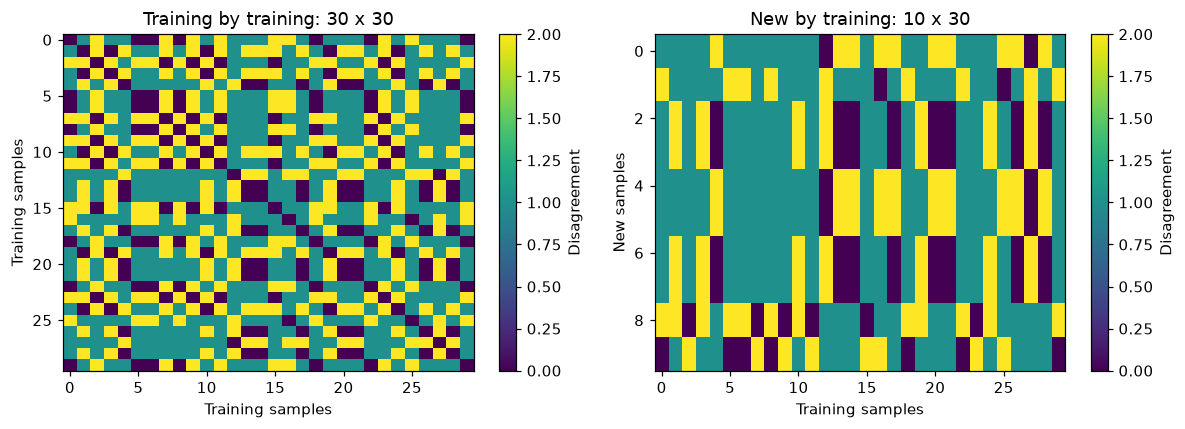

In [5]:
single_output, intermediate = model.transform(one_sample, return_intermediates=True)
expected_scale = (one_sample['gene'].to_numpy() - train_views['gene'].mean().to_numpy()) / (
    train_views['gene'].std(ddof=0).replace(0, 1).to_numpy())
assert np.allclose(intermediate['gene_scale'], expected_scale)
assert not np.allclose(intermediate['gene_scale'], 0)
assert single_output['distance'].shape == (1, 30)
new_output = model.transform(test_views)
assert new_output['distance'].shape == (10, 30)
assert training_result['distance'].shape == (30, 30)
display(pd.DataFrame(single_output['distance'], index=one_sample['gene'].index,
                     columns=train_views['gene'].index))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, matrix, title in zip(axes, [training_result['distance'], new_output['distance']],
                           ['Training by training: 30 x 30', 'New by training: 10 x 30']):
    image = ax.imshow(matrix, aspect='auto', vmin=0, vmax=2, cmap='viridis')
    ax.set(title=title, xlabel='Training samples',
           ylabel='Training samples' if matrix.shape[0] == 30 else 'New samples')
    fig.colorbar(image, ax=ax, label='Disagreement')
fig.tight_layout()
plt.show()

## 6. Evaluate after assignment

The annotations enter only this reporting step. NMI and AMI describe agreement
with genotype, while diet NMI shows a second factor. These are exploratory
results from one random split of a small dataset. The held-out and training
scores concern different subsets and do not establish clinical performance.
They are also different experiments from the original full-data notebook.

In [6]:
rows = []
for split, index, labels in [('Training', train_views['gene'].index, training_labels),
                             ('Held out', test_views['gene'].index, batch_labels)]:
    truth = annotations.loc[index]
    rows.append({'split': split, 'samples': len(index), 'observed_clusters': len(np.unique(labels)),
                 'NMI_genotype': normalized_mutual_info_score(truth['genotype'], labels),
                 'AMI_genotype': adjusted_mutual_info_score(truth['genotype'], labels),
                 'NMI_diet': normalized_mutual_info_score(truth['diet'], labels)})
summary = pd.DataFrame(rows).set_index('split')
display(summary.round(4))
assigned = annotations.loc[test_views['gene'].index].copy()
assigned['predicted_cluster'] = batch_labels
display(assigned)
assert np.isfinite(summary.select_dtypes(include='number')).all().all()

,samples,observed_clusters,NMI_genotype,AMI_genotype,NMI_diet
split,,,,,
Training,30,2,0.1618,0.1400,0.0604
Held out,10,2,0.4325,0.3744,0.1400


,genotype,diet,predicted_cluster
sample,,,
mouse_19,wt,ref,1
mouse_16,wt,coc,2
mouse_15,wt,lin,2
mouse_26,ppar,ref,2
mouse_04,wt,ref,1
mouse_12,wt,sun,1
mouse_37,ppar,fish,2
mouse_27,ppar,lin,2
mouse_39,ppar,sun,2


## 7. Use a native prediction method when available

`nn.Estimator` retains an estimator with native `predict()`, such as KMeans.
`nn.Transform` similarly adapts any suitable sklearn-style transformer. The
following single-view example uses the same training subset and is included to
show native inference. It does not select a replacement model using test scores.

In [7]:
source = nn.Input('gene')
features = nn.Standardize(name='scale')(source)
partition = nn.Estimator(KMeans(n_clusters=2, n_init=10, random_state=SEED), name='kmeans')(features)
native = nn.Graph({'gene': source}, partition).fit(gene=train_views['gene'])
native_one = native.predict(gene=one_sample['gene'])
native_batch = native.predict(gene=test_views['gene'])
assert np.array_equal(native_one, native_batch[:1])
assert np.isin(native_batch, native.labels_).all()
print('Native KMeans assignment for the first held-out sample:', native_one[0])

Native KMeans assignment for the first held-out sample: 0


## 8. Persist the model and keep configuration changes explicit

The fitted snapshot contains all references and preprocessing needed for
prediction. The comparison below checks that inference did not change any of
the serialized model state. A pickle round trip retains predictions.

`with_params()` returns an unfitted configuration copy. Fit that copy before
prediction; its changed configuration does not reuse a stale fitted state.
After a genetic search, likewise fit `search.best_graph` on the training subset.

Custom operations must implement `fit_forward` and `predict_forward`. Arbitrary
transductive functions are rejected unless explicitly declared to be stateless,
sample-wise operations. Ordinary graph calls and `run()` still recluster their
inputs; use `predict()` for the frozen model.

In [8]:
assert pickle.dumps(model) == frozen_snapshot
assert model.get_params() == configuration_before_prediction
assert np.array_equal(model.labels_, training_labels)
restored = pickle.loads(frozen_snapshot)
assert np.array_equal(restored.predict(test_views), batch_labels)
changed = model.with_params(gene_cluster__n_clusters=4)
try:
    changed.predict(one_sample)
except NotFittedError as error:
    print('Expected for a changed, unfitted configuration:', error)
else:
    raise AssertionError('Changed configuration reused old training state')
print('Verified frozen state, serialization, and parameter-copy invalidation.')
print('Completed: {} training samples, {} held-out samples, single-row and batch inference.'.format(
    model.n_samples_fit_, len(test_indices)))

Expected for a changed, unfitted configuration: Call Graph.fit() before inductive prediction
Verified frozen state, serialization, and parameter-copy invalidation.
Completed: 30 training samples, 10 held-out samples, single-row and batch inference.


## Further work

Assignment rules, preprocessing, and hyperparameters should be chosen using
training-only analyses. Larger held-out cohorts, repeated splits, stability,
and appropriate external annotations are needed to assess assignment quality.
The current rules always assign an existing learned label; they do not provide
novelty detection or calibrated confidence. Medoid and average transfer can
reassign some training points when called through `predict`, so `labels_` and
`fit_predict()` are the recorded training partition.

References and provenance:

- [Original Nutrimouse notebook](Nutrimouse.ipynb).
- [Graph API and Parea 2 replay](Nutrimouse_Graphs.ipynb).
- [Data source, citations, license, and checksums](data/nutrimouse/README.md).
- [Inductive assignment definitions](../docs/source/inductive.rst).